# Reseek decoy simulation: are the p-values calibrated?

The same experiment as `foldseek_sim.ipynb`, for Reseek. `reseek -search -num_shuffles N`
shuffles the query `N` times internally and searches every decoy against SCOP40. Each
decoy's best hit is a null draw, so calibrated values are Uniform(0, 1) and fall on the
diagonal of a log-log QQ plot. We compare Reseek's E-value and P-value with the SG
p-value computed from the AQ score.

| Step | What | Output in `results/simulation/reseek/<tag>/` |
|---|---|---|
| 1 | convert the query to `.bca` (only for a structure input) | `query.bca` |
| 2 | decoy search (`reseek -search -num_shuffles`) | `search.tsv` |
| 3 | best hit per decoy, by AQ, by E-value and by P-value | `sorted.tsv`, `sorted_evalue.tsv`, `sorted_pvalue.tsv` |
| 4 | SG p-value per decoy | `sgpvalue.tsv` |
| 5 | QQ plots | `qqplot_Evalue.pdf`, `qqplot_Pvalue.pdf`, `qqplot_SGPvalue.pdf` |

**Before you start:** run this notebook from `tutorial/`. From Zenodo, unpack these at
the repository root:
- `results_simulation.tar.gz` gives `results/simulation/`, the paper's best-hit tables.
  With it, the notebook goes straight to the plots.
- To rerun the decoy searches, you also need `data_simulation.tar.gz` (queries and SCOP40
  targets in `data/simulation/`) and the tools from `bash scripts/build.sh`. With 200,000
  decoys, one query takes about **a day**.

Reseek's shuffling cannot be seeded, so every new search draws new decoys; keep
`search.tsv` to regenerate a figure exactly.

With `USE_CACHED = True` (the default), every step whose output already exists is skipped.
With the Zenodo results unpacked, the notebook only draws the plots. The table after the
parameters shows what will be reused and what will be computed. Set `USE_CACHED = False`
to recompute everything.

## Parameters

In [1]:
from pathlib import Path
import os
if not Path('scripts/build.sh').exists():   # opened from tutorial/: work from the repository root
    os.chdir('..')
ROOT = Path('.')                            # all paths below are relative to the repository root

RESEEK    = ROOT / 'bin/reseek'
TARGET_DB = ROOT / 'data/simulation/scop_target.bca'
LOOKUP    = ROOT / 'data/lookup/m50.txt'
OUTROOT   = ROOT / 'results/simulation/reseek'

# (query .bca or structure, tag, amino-acid length): the five SCOP domains used in the paper
QUERIES = [
    ('data/simulation/queries/d1za_30.bca',  'd1za_30',  30),
    ('data/simulation/queries/d1st_87.bca',  'd1st_87',  87),
    ('data/simulation/queries/d2ao_120.bca', 'd2ao_120', 120),
    ('data/simulation/queries/d1ku_151.bca', 'd1ku_151', 151),
    ('data/simulation/queries/d2uy_288.bca', 'd2uy_288', 288),
]

NUM_SHUFFLES = 200_000   # decoys per query
EVALUE       = 100       # reseek -evalue
THREADS      = None      # reseek -threads (None = reseek default)
N_NULL       = 50        # null sample size; must match LOOKUP (m50 -> 50)
SG_SEED      = 0         # seed for drawing the null samples in step 4
USE_CACHED   = True      # reuse outputs already in OUTROOT (e.g. the Zenodo results); False = recompute all

In [2]:
import csv
import os
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

matplotlib.rcParams['pdf.fonttype'] = 42   # keep PDF text as text
matplotlib.rcParams['ps.fonttype'] = 42


def run(cmd, log=None):
    """Run an external command; stream nothing, keep its output in `log`, fail loudly."""
    cmd = [str(c) for c in cmd]
    print('$', ' '.join(cmd))
    with open(log, 'w') if log else open(os.devnull, 'w') as fh:
        subprocess.run(cmd, check=True, stdout=fh, stderr=subprocess.STDOUT)


def needs(path):
    """True if `path` must be (re)computed: USE_CACHED is off, or the file is missing/empty."""
    return not USE_CACHED or not Path(path).exists() or Path(path).stat().st_size == 0


def cached(path):
    print(f'cached: {path}')


### What will run

In [3]:
PROCESSED = ['sorted.tsv', 'sorted_evalue.tsv', 'sorted_pvalue.tsv']


def search_needed(tag):
    """The decoy search runs only if neither it nor its best-hit tables are cached."""
    out = OUTROOT / tag
    return needs(out / 'search.tsv') and any(needs(out / f) for f in PROCESSED)


rows = []
for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    have = {step: not needs(out / f) for step, f in
            [('decoy search', 'search.tsv'), ('best hits (AQ)', 'sorted.tsv'), ('best hits (E-value)', 'sorted_evalue.tsv'),
             ('best hits (P-value)', 'sorted_pvalue.tsv'), ('SG p-values', 'sgpvalue.tsv')]}
    todo = ('search (~1 day) + analysis' if search_needed(tag)
            else 'plots only' if all(list(have.values())[1:]) else 'analysis')
    rows.append({'query': tag, **{k: 'cached' if v else '-' for k, v in have.items()}, 'will run': todo})
pd.DataFrame(rows)

,query,decoy search,best hits (AQ),best hits (E-value),best hits (P-value),SG p-values,will run
0,d1za_30,-,cached,cached,cached,cached,plots only
1,d1st_87,-,cached,cached,cached,cached,plots only
2,d2ao_120,-,cached,cached,cached,cached,plots only
3,d1ku_151,-,cached,cached,cached,cached,plots only
4,d2uy_288,-,cached,cached,cached,cached,plots only


## 1. Query in Reseek format

In [4]:
query_bca = {}
for query, tag, _ in QUERIES:
    out = OUTROOT / tag
    out.mkdir(parents=True, exist_ok=True)
    if not search_needed(tag):
        print(f'{tag}: query conversion not needed (search results cached)')
        continue
    if query.endswith('.bca'):
        query_bca[tag] = ROOT / query
    else:
        query_bca[tag] = out / 'query.bca'
        if needs(query_bca[tag]):
            run([RESEEK, '-convert', ROOT / query, '-bca', query_bca[tag]], log=out / 'convert.log')

d1za_30: query conversion not needed (search results cached)
d1st_87: query conversion not needed (search results cached)
d2ao_120: query conversion not needed (search results cached)
d1ku_151: query conversion not needed (search results cached)
d2uy_288: query conversion not needed (search results cached)


## 2. Decoy search

Decoys are named `<query chain>_shuffle<N>`. Only decoy hits are reported.

In [5]:
for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    if not search_needed(tag):
        cached(out / 'search.tsv' if (out / 'search.tsv').exists() else out / 'sorted.tsv')
    else:
        cmd = [RESEEK, '-search', query_bca[tag], '-db', TARGET_DB, '-verysensitive',
               '-num_shuffles', NUM_SHUFFLES, '-columns', 'aq+query+target+evalue+pvalue',
               '-evalue', EVALUE, '-output', out / 'search.tsv']
        if THREADS:
            cmd += ['-threads', THREADS]
        run(cmd, log=out / 'search.log')

first = OUTROOT / QUERIES[0][1] / 'search.tsv'
if first.exists():
    display(pd.read_csv(first, sep='\t', nrows=5, names=['aq', 'query', 'target', 'evalue', 'pvalue']))

cached: results/simulation/reseek/d1za_30/sorted.tsv
cached: results/simulation/reseek/d1st_87/sorted.tsv
cached: results/simulation/reseek/d2ao_120/sorted.tsv
cached: results/simulation/reseek/d1ku_151/sorted.tsv
cached: results/simulation/reseek/d2uy_288/sorted.tsv


## 3. Best hit per decoy

Keep one row per decoy: the highest AQ (input to the SG p-value), or the smallest
E-value or P-value (for their QQ plots).

In [6]:
def best_hit_per_decoy(input_path, output_path, metric):
    """metric = 'aq' (keep max, sort descending), 'evalue' or 'pvalue' (keep min, sort ascending)."""
    best_hits = {}
    with open(input_path, 'r') as f:
        reader = csv.reader(f, delimiter='\t')
        for row in reader:
            if len(row) < 5:
                continue
            query = row[1]
            try:
                aq = float(row[0])
                evalue = float(row[3])
                pvalue = float(row[4])
            except ValueError:
                continue
            sort_val = {'aq': aq, 'evalue': evalue, 'pvalue': pvalue}[metric]
            if query not in best_hits:
                best_hits[query] = (sort_val, row)
            else:
                prev_val, _ = best_hits[query]
                if (metric == 'aq' and sort_val > prev_val) or (metric != 'aq' and sort_val < prev_val):
                    best_hits[query] = (sort_val, row)

    sorted_hits = sorted(best_hits.items(), key=lambda x: x[1][0], reverse=(metric == 'aq'))
    with open(output_path, 'w') as out_f:
        writer = csv.writer(out_f, delimiter='\t', lineterminator='\n')
        writer.writerow(['AQ', 'Query', 'Target', 'evalue', 'Pvalue'])
        for _, (_, row) in sorted_hits:
            writer.writerow(row)
    print(f'{len(sorted_hits):,} decoys (best by {metric}) -> {output_path}')


for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    for name, metric in zip(PROCESSED, ['aq', 'evalue', 'pvalue']):
        if needs(out / name):
            best_hit_per_decoy(out / 'search.tsv', out / name, metric)
        else:
            cached(out / name)

cached: results/simulation/reseek/d1za_30/sorted.tsv
cached: results/simulation/reseek/d1za_30/sorted_evalue.tsv
cached: results/simulation/reseek/d1za_30/sorted_pvalue.tsv
cached: results/simulation/reseek/d1st_87/sorted.tsv
cached: results/simulation/reseek/d1st_87/sorted_evalue.tsv
cached: results/simulation/reseek/d1st_87/sorted_pvalue.tsv
cached: results/simulation/reseek/d2ao_120/sorted.tsv
cached: results/simulation/reseek/d2ao_120/sorted_evalue.tsv
cached: results/simulation/reseek/d2ao_120/sorted_pvalue.tsv
cached: results/simulation/reseek/d1ku_151/sorted.tsv
cached: results/simulation/reseek/d1ku_151/sorted_evalue.tsv
cached: results/simulation/reseek/d1ku_151/sorted_pvalue.tsv
cached: results/simulation/reseek/d2uy_288/sorted.tsv
cached: results/simulation/reseek/d2uy_288/sorted_evalue.tsv
cached: results/simulation/reseek/d2uy_288/sorted_pvalue.tsv


## 4. SG p-value per decoy

Every decoy's best AQ score $S_i$ is a draw from the null. Following Lu, Noble & Keich
(*Bioinformatics* 2024, §2.3.4.1), each $S_i$ is scored against `N_NULL` other decoy scores
drawn **with replacement** from the pool (excluding $S_i$ itself):

$$\hat s_i = \frac{S_i - \overline{Y}}{\operatorname{sd}(Y)}, \qquad
p_i = \text{SG lookup}(\hat s_i)$$

The SG lookup table (`data/lookup/m50.txt`) maps $\hat s$ to the Studentized-Gumbel p-value
for a null sample of size 50. If SG p-values are calibrated, the $p_i$ are Uniform(0, 1).
The output is sorted by p-value: `i, query, S_i, null_mean, null_std, s_hat, sg_pvalue`.

In [7]:
def load_lookup(lookup_path):
    """SG lookup table: 2 space-delimited columns (s_hat key, p-value)."""
    lookup_mat = np.loadtxt(lookup_path)
    lookup_keys = lookup_mat[:, 0].flatten()
    return lookup_keys, lookup_mat


def sg_pvalue_from_shat(s_hat, lookup_keys, lookup_mat):
    """Nearest table key -> SG p-value."""
    s_hat_key = np.floor(s_hat * 1000.0) / 1000.0
    hit_index = np.argmin(np.fabs(lookup_keys - s_hat_key))
    return float(lookup_mat[hit_index, 1])


def load_scores(tsv_path, score_col, query_col, header=True):
    """(decoy ids, best scores) from a best-hit-per-decoy TSV."""
    queries, scores = [], []
    with open(tsv_path, 'r') as f:
        reader = csv.reader(f, delimiter='\t')
        if header:
            next(reader, None)
        for row in reader:
            if len(row) <= max(score_col, query_col):
                continue
            try:
                scores.append(float(row[score_col]))
                queries.append(row[query_col].strip())
            except ValueError:
                continue
    return queries, np.array(scores, dtype=float)


def sg_pvalues(sorted_tsv, output_tsv, lookup, n_null, seed, score_col, query_col):
    lookup_keys, lookup_mat = load_lookup(lookup)
    queries, scores = load_scores(sorted_tsv, score_col=score_col, query_col=query_col)
    N = len(scores)
    assert n_null < N, f'n_null ({n_null}) must be < number of decoys ({N})'

    rng = np.random.default_rng(seed)
    rows = []
    for i in range(N):
        S_i = scores[i]
        pool = np.delete(scores, i)                                  # exclude self
        null_sample = rng.choice(pool, size=n_null, replace=True)    # with replacement
        null_mean = np.mean(null_sample)
        null_std = np.std(null_sample)                               # population std (ddof=0)
        s_hat = 0.0 if null_std == 0.0 else (S_i - null_mean) / null_std
        sg_pv = sg_pvalue_from_shat(s_hat, lookup_keys, lookup_mat)
        rows.append((i + 1, queries[i], f'{S_i:.6f}', f'{null_mean:.6f}',
                     f'{null_std:.6f}', f'{s_hat:.6f}', sg_pv))

    rows.sort(key=lambda r: r[6])
    with open(output_tsv, 'w', newline='') as out_f:
        writer = csv.writer(out_f, delimiter='\t', lineterminator='\n')
        writer.writerow(['i', 'query', 'S_i', 'null_mean', 'null_std', 's_hat', 'sg_pvalue'])
        for row in rows:
            writer.writerow([row[0], row[1], row[2], row[3], row[4], row[5], f'{row[6]:.6e}'])
    print(f'{N:,} SG p-values -> {output_tsv}')


for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    if not needs(out / 'sgpvalue.tsv'):
        cached(out / 'sgpvalue.tsv')
        continue
    sg_pvalues(out / 'sorted.tsv', out / 'sgpvalue.tsv', LOOKUP,
               n_null=N_NULL, seed=SG_SEED, score_col=0, query_col=1)

cached: results/simulation/reseek/d1za_30/sgpvalue.tsv
cached: results/simulation/reseek/d1st_87/sgpvalue.tsv
cached: results/simulation/reseek/d2ao_120/sgpvalue.tsv
cached: results/simulation/reseek/d1ku_151/sgpvalue.tsv
cached: results/simulation/reseek/d2uy_288/sgpvalue.tsv


## 5. QQ plots

Points on the red diagonal mean calibrated. Points **below** it are anti-conservative.
Each panel is also saved as a 7×7 in PDF next to the results.

In [8]:
def draw_qq_sgpvalue(ax, df, title, pmax=0.432):
    """log-log QQ plot of SG p-values vs Uniform(0,1).

    The lookup table's largest p-value (0.432 for n_null = 50, i.e. "no evidence") is
    collapsed to 1 and drawn as a single point at (0, 0)."""
    df = df.copy()
    df['sg_pvalue'] = df['sg_pvalue'].replace([pmax], 1)
    n = len(df)
    df_sorted = df.sort_values('sg_pvalue').reset_index(drop=True)
    df_sorted['normalized_rank'] = (np.arange(1, n + 1)) / n
    df_sorted['log10_sg_pvalue'] = np.log10(df_sorted['sg_pvalue'])
    df_sorted['log10_rank'] = np.log10(df_sorted['normalized_rank'])

    x, y = df_sorted['log10_rank'], df_sorted['log10_sg_pvalue']
    overall_min = min(x.min(), y.min())
    overall_max = max(x.max(), y.max())

    mask_one = df_sorted['sg_pvalue'] == 1
    df_bulk = df_sorted[~mask_one]
    ax.scatter(df_bulk['log10_rank'], df_bulk['log10_sg_pvalue'],
               alpha=0.5, color='steelblue', s=15, rasterized=True)
    ax.scatter([0], [0], alpha=1.0, color='steelblue', s=40, zorder=5)
    pad = (overall_max - overall_min) * 0.05
    ax.plot([overall_min, overall_max + pad], [overall_min, overall_max + pad],
            'r--', linewidth=2, label='y=x')
    ax.set_xlim(overall_min, overall_max + pad)
    ax.set_ylim(overall_min, overall_max + pad)
    ax.grid(False)
    ax.set_xlabel('log₁₀(Normalized Rank (i/n))')
    ax.set_ylabel('log₁₀(SG-Pvalue)')
    ax.set_title(title.format(n=n))
    return df_sorted


def draw_qq_evalue(ax, df, title, col='Evalue', label='E-value'):
    """log-log QQ plot of a tool-reported E-value (or P-value) vs Uniform(0,1)."""
    n = len(df)
    df_sorted = df.sort_values(col).reset_index(drop=True)
    df_sorted['normalized_rank'] = (np.arange(1, n + 1)) / n
    df_sorted['log10_value'] = np.log10(df_sorted[col])
    df_sorted['log10_rank'] = np.log10(df_sorted['normalized_rank'])

    x, y = df_sorted['log10_rank'], df_sorted['log10_value']
    overall_min = min(x.min(), y.min())
    overall_max = max(x.max(), y.max())

    ax.scatter(x, y, alpha=0.1, color='steelblue', s=15, rasterized=True)
    ax.plot([overall_min, overall_max], [overall_min, overall_max],
            'r--', linewidth=2, label='y=x')
    ax.set_xlim(overall_min, overall_max)
    ax.set_ylim(overall_min, overall_max)
    ax.grid(False)
    ax.set_xlabel('log₁₀(Normalized Rank (i/n))')
    ax.set_ylabel(f'log₁₀({label})')
    ax.set_title(title.format(n=n))
    return df_sorted


def save_qq(draw, df, title, pdf, **kw):
    """Save one 7x7 in QQ plot as a PDF."""
    fig, ax = plt.subplots(figsize=(7, 7))
    draw(ax, df, title, **kw)
    fig.savefig(pdf, format='pdf', bbox_inches='tight')
    plt.close(fig)


def n_label(n):
    return f'{n // 1000}K' if n % 1000 == 0 else str(n)


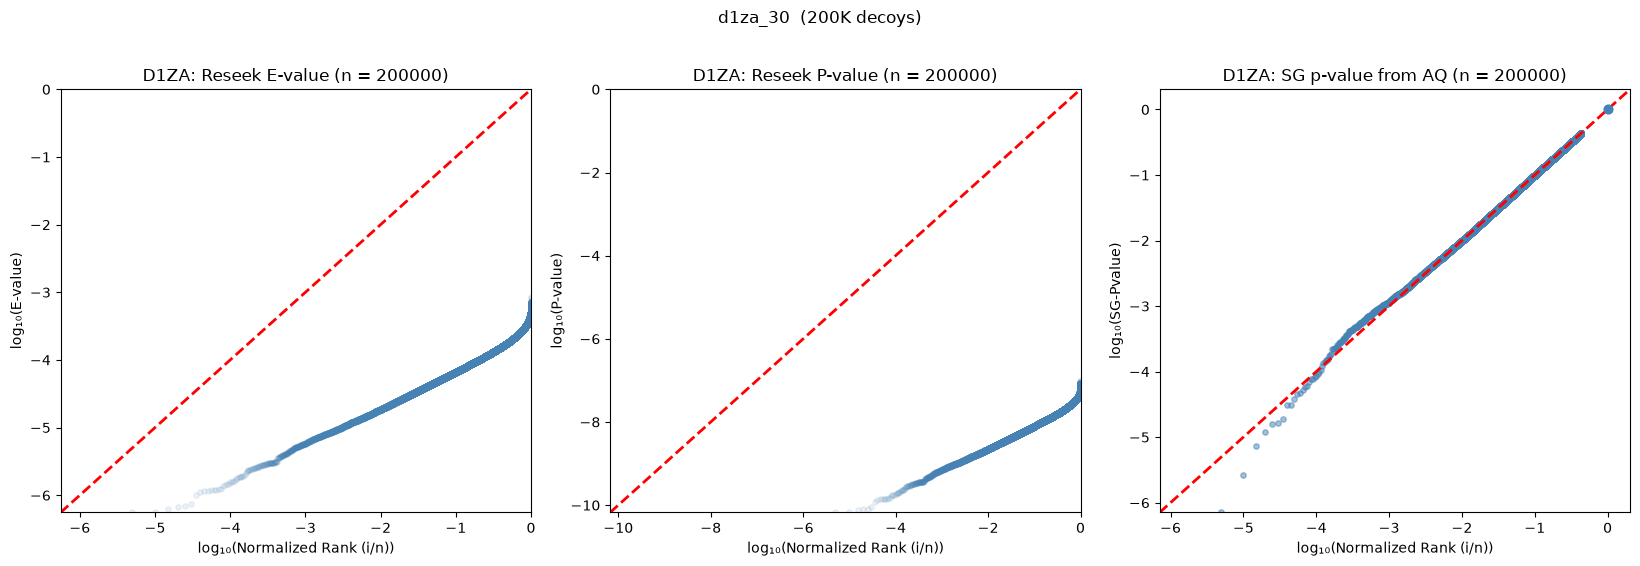

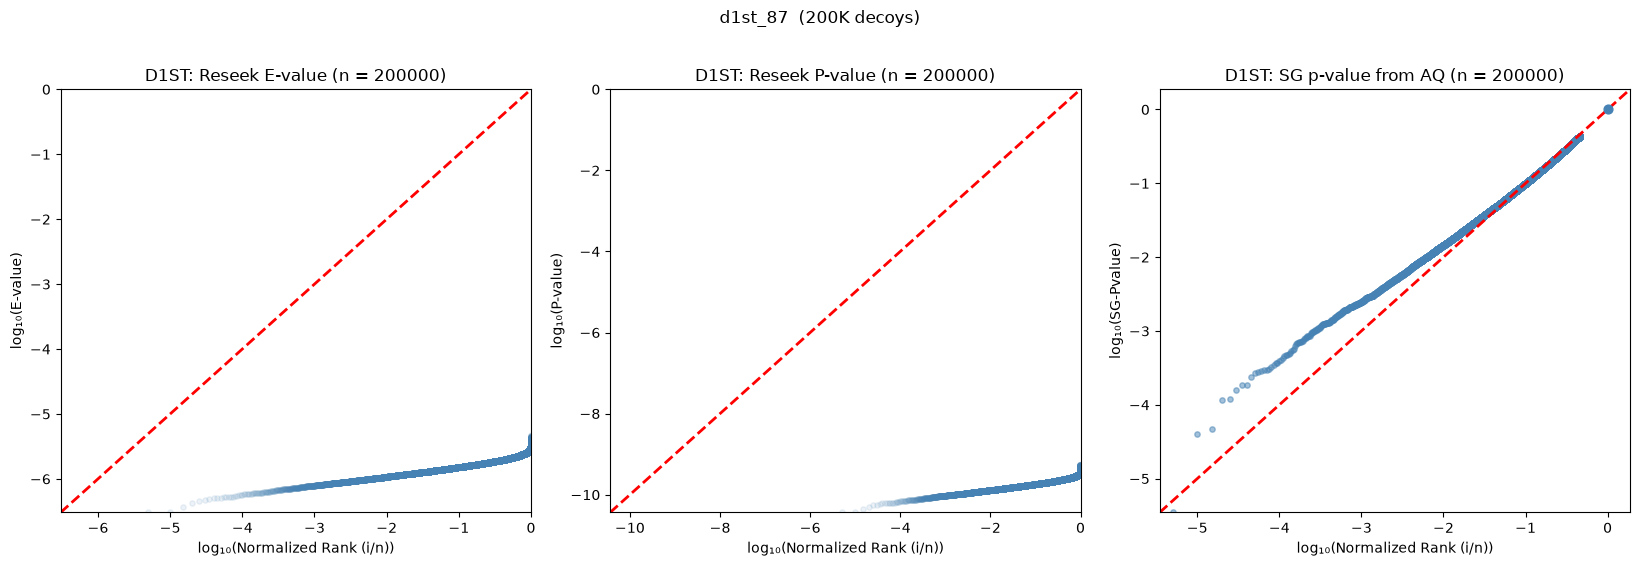

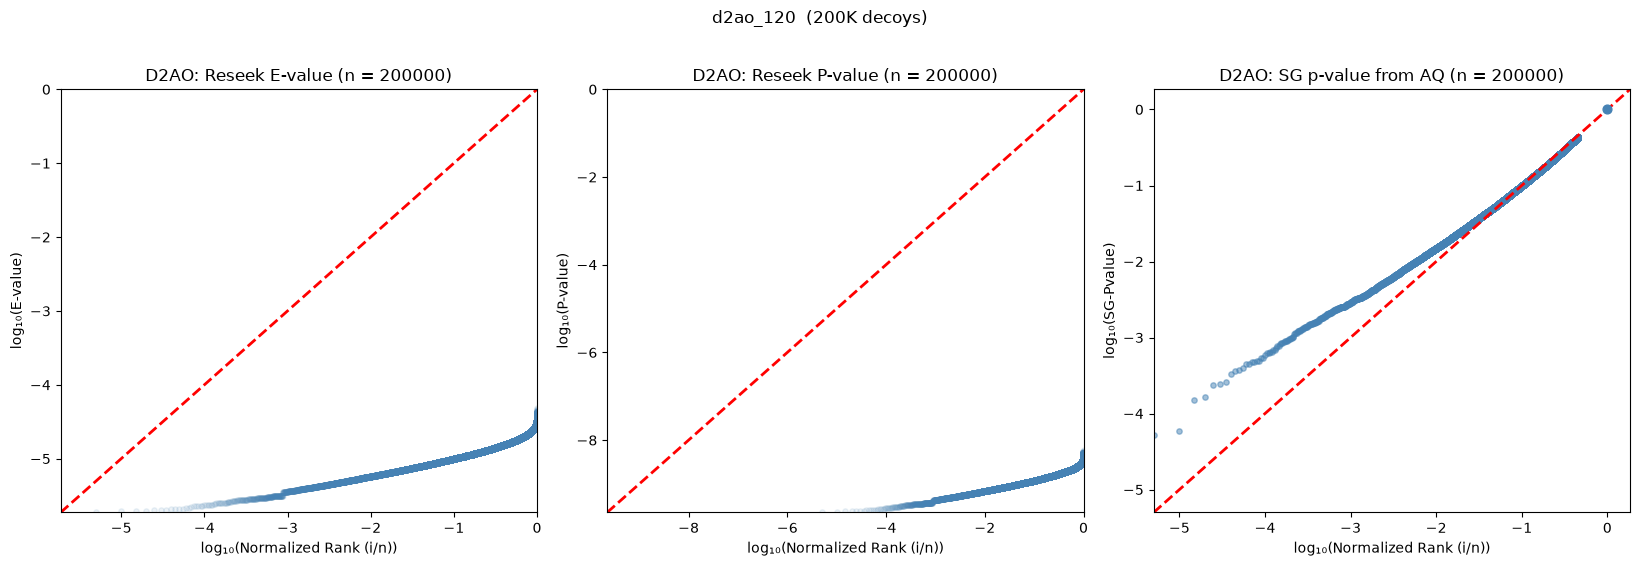

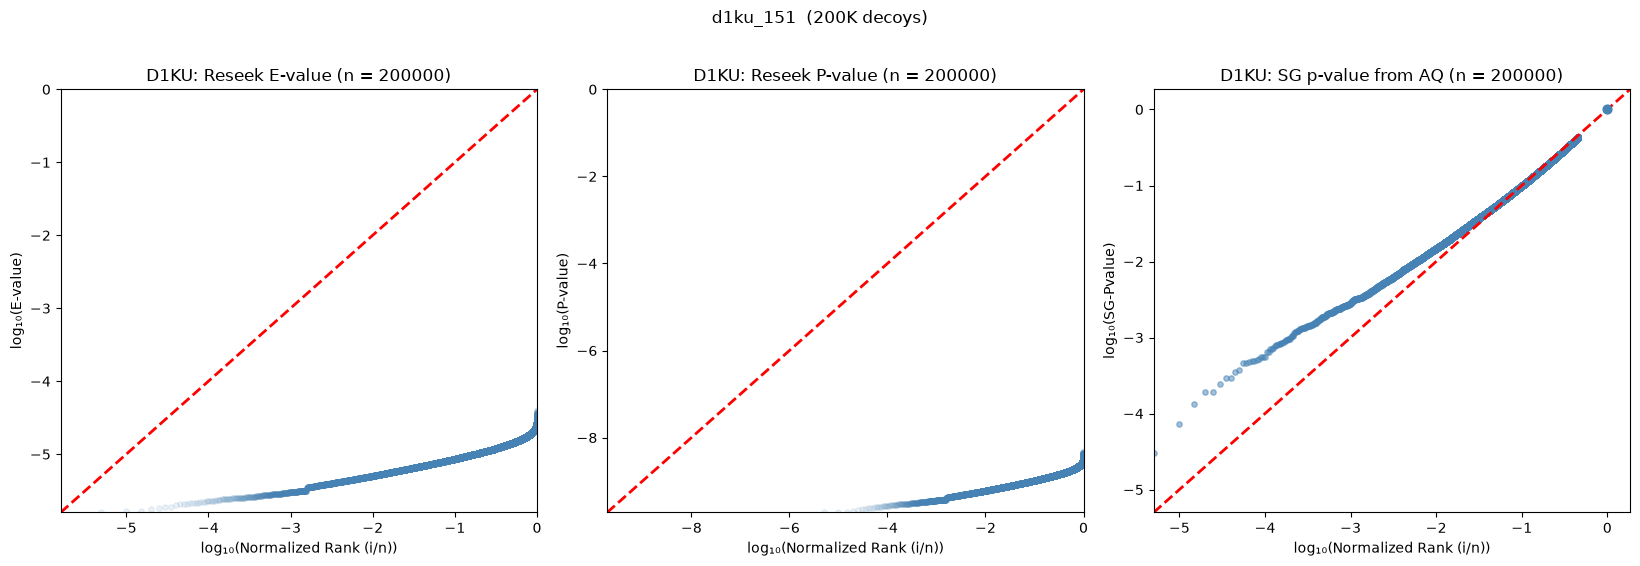

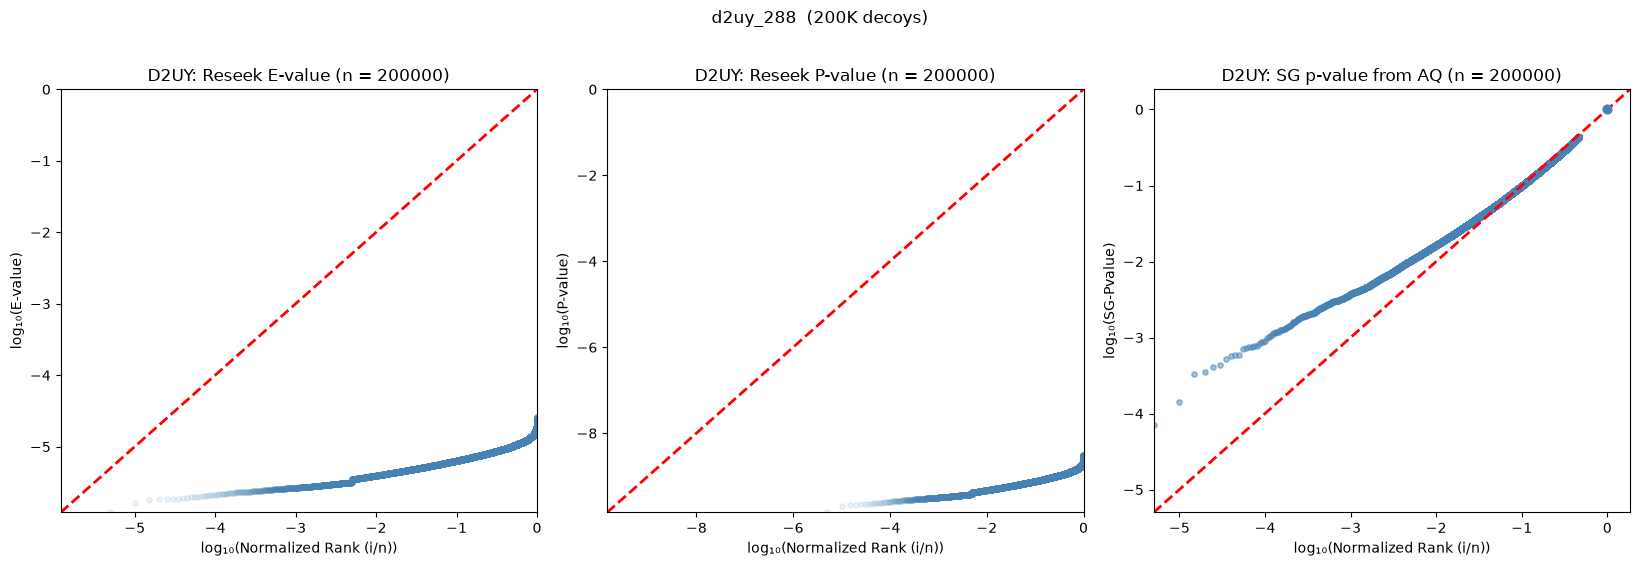

In [9]:
for _, tag, aa_len in QUERIES:
    out = OUTROOT / tag
    name = tag.split('_')[0].upper()
    ev = pd.read_csv(out / 'sorted_evalue.tsv', sep='\t')
    pv = pd.read_csv(out / 'sorted_pvalue.tsv', sep='\t')
    sg = pd.read_csv(out / 'sgpvalue.tsv', sep='\t')
    head = f'vs {n_label(NUM_SHUFFLES)} for {name} (AA: {aa_len}, Reseek'
    save_qq(draw_qq_evalue, ev, f'QQ Plot: E-value {head} E-value) (n = {{n}})',
            out / 'qqplot_Evalue.pdf', col='evalue', label='E-value')
    save_qq(draw_qq_evalue, pv, f'QQ Plot: P-value {head} P-value) (n = {{n}})',
            out / 'qqplot_Pvalue.pdf', col='Pvalue', label='P-value')
    save_qq(draw_qq_sgpvalue, sg, f'QQ Plot: SG-Pvalue {head} AQ) (n = {{n}})',
            out / 'qqplot_SGPvalue.pdf')

    fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.5))
    draw_qq_evalue(axes[0], ev, f'{name}: Reseek E-value (n = {{n}})', col='evalue', label='E-value')
    draw_qq_evalue(axes[1], pv, f'{name}: Reseek P-value (n = {{n}})', col='Pvalue', label='P-value')
    draw_qq_sgpvalue(axes[2], sg, f'{name}: SG p-value from AQ (n = {{n}})')
    fig.suptitle(f'{tag}  ({n_label(NUM_SHUFFLES)} decoys)', y=1.02)
    fig.tight_layout()
    plt.show()